[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Tamaño del efecto.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo III: *Inferencia estadística*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se reportará el tamaño del efecto (d de Cohen, V de Cramér y η²) junto con el valor *p* y se integrarán las pruebas de hipótesis vistas en el módulo.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* 🟢 **Ejercicio básico:** lo que todos deben dominar.
* 🔴 **Reto (opcional):** para quien termina antes o quiere profundizar. Si no da tiempo en clase, se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencias.

py311 no cubre inferencia, así que la referencia de la API es la documentación oficial: [*SciPy* · `scipy.stats`](https://docs.scipy.org/doc/scipy/reference/stats.html) (`ttest_ind`, `mannwhitneyu`, `permutation_test`, `chi2_contingency`, `f_oneway`, `levene`), [*statsmodels* · pruebas de proporciones](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportions_ztest.html), [*statsmodels* · `pairwise_tukeyhsd`](https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html) y [*statsmodels* · `anova_oneway`](https://www.statsmodels.org/stable/generated/statsmodels.stats.oneway.anova_oneway.html).

### Preparación del entorno.

* La siguiente celda importará las bibliotecas y las funciones de *SciPy* y *statsmodels* que se usarán, y definirá `DATA` y la semilla `rng`.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.proportion import proportions_ztest

* La siguiente celda leerá `penguins_limpio.csv` (o lo regenerará si no existe), `titanic.csv` y `tips.csv`, y creará `tip_pct`.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio)
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
propinas = pd.read_csv(os.path.join(DATA, "tips.csv")).assign(tip_pct=lambda d: 100 * d["tip"] / d["total_bill"])
pinguinos.shape, titanic.shape, propinas.shape

((342, 7), (891, 15), (244, 8))

### Objetos de los *notebooks* anteriores.

Este *notebook* es independiente: la siguiente celda vuelve a crear lo que se necesita de los *notebooks* anteriores.

* La siguiente celda definirá `d_cohen` y `eta_cuadrada`, presentadas en `20_pruebas_para_dos_grupos.ipynb` y `21_proporciones_y_mas_de_dos_grupos.ipynb`, y la tabla `tabla_clase` de `class` contra `survived`.

In [3]:
def d_cohen(a, b):
    a, b = np.asarray(a), np.asarray(b)
    varianza_combinada = ((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2)
    return (a.mean() - b.mean()) / np.sqrt(varianza_combinada)


def eta_cuadrada(valores, grupos):
    datos = pd.DataFrame({"valor": valores, "grupo": grupos}).dropna()
    media_global = datos["valor"].mean()
    por_grupo = datos.groupby("grupo")["valor"].agg(["count", "mean"])
    suma_entre = (por_grupo["count"] * (por_grupo["mean"] - media_global) ** 2).sum()
    suma_total = ((datos["valor"] - media_global) ** 2).sum()
    return suma_entre / suma_total


tabla_clase = pd.crosstab(titanic["class"], titanic["survived"])
tabla_clase

survived,0,1
class,,
First,80,136
Second,97,87
Third,372,119


---
## 1. Tamaño del efecto y ejercicios de este *notebook* (20 min).

| Situación | Prueba | Tamaño del efecto |
|---|---|---|
| Dos medias | Welch | d de Cohen (y la diferencia con su IC, en unidades originales) |
| Dos distribuciones asimétricas | Mann-Whitney o permutación de medianas | Diferencia de medianas con IC *bootstrap* |
| Dos proporciones | *z* de proporciones | Diferencia de proporciones o riesgo relativo |
| Dos categóricas | Chi cuadrada | V de Cramér |
| Tres o más medias | ANOVA (Welch si las varianzas difieren) + Tukey | η² |

**Plantilla para redactar:** "En estos datos, [grupo A] tuvo [medida] [mayor/menor] que [grupo B] ([valor A] contra [valor B]; diferencia de [valor y unidades], IC 95% [a, b]; [prueba], *p* [valor]; [tamaño del efecto: d de Cohen, V de Cramér o η²] = [valor], un efecto [magnitud])." Sin verbos causales ("provoca", "hace que") cuando los datos son observacionales.

**¿Por qué hace falta el tamaño del efecto?** Un valor *p* chico dice que una diferencia así sería rara si, en promedio, los grupos fueran iguales; no dice cuánto difieren ni si importa. Con muestras enormes basta una diferencia diminuta para obtener un valor *p* chico (en `21_proporciones_y_mas_de_dos_grupos.ipynb` se simula un caso con *p* ≈ 8×10⁻⁶ y d ≈ 0.02): se detecta, pero es demasiado pequeña para que importe en la práctica. El tamaño del efecto contesta la otra pregunta, «¿cuánto?», y se puede dar de **tres maneras**:
* en las **unidades originales**: los machos Adelie pesan unos 675 g más que las hembras;
* en **desviaciones estándar** (la d de Cohen): d = 2.17;
* en **frecuencias naturales**: en unas 94 de cada 100 parejas macho–hembra de Adelie, el macho pesa más.

**Las escalas son orientativas.** Los valores 0.2, 0.5 y 0.8 de la d son convenciones de aproximación: una d de 0.2 puede ser muy importante en salud pública y una de 0.8 irrelevante para otra decisión. Siempre se leen junto con la pregunta que se quiere contestar. Las escalas de V de Cramér (0.1, 0.3 y 0.5, solo para tablas con 2 filas o 2 columnas) y de η² (0.01, 0.06 y 0.14) están en `21_proporciones_y_mas_de_dos_grupos.ipynb`; V no es un porcentaje.

**Un contraste con datos reales.** Los Chinstrap y los Adelie difieren en 32 g de masa media (*p* = 0.59, d = 0.07: un efecto pequeño o nulo; el intervalo de la diferencia, de −86 a 150 g, no descarta diferencias de hasta unos 150 g), y los fumadores y no fumadores de `tips` dejan 16.3% y 15.9% de propina (*p* = 0.68, d = 0.06). En ambos casos no hay evidencia de un efecto, y se ven muy distintos de los 675 g y la d de 2.17 de los Adelie.

**¿Por qué esta sección?** El producto final de una prueba no es el valor *p*, sino una **frase** que una persona sin formación estadística pueda leer y que no exagere. La tabla resume qué tamaño del efecto acompaña a cada prueba, y la plantilla sirve para redactar los hallazgos de un informe (como en `25_estructura_del_informe_y_comunicacion.ipynb` y `26_del_notebook_al_informe.ipynb`).

**💡 Ideas clave de la sección 1:** cada prueba tiene su tamaño del efecto; se reporta magnitud, IC, prueba y valor *p*, en lenguaje descriptivo.

### 🟢 Ejercicio 1a · Masa por sexo en Adelie.

**🎯 Objetivo:** redactar un resultado con la plantilla. **Qué se espera aprender:** a comunicar magnitud, incertidumbre y prueba en una sola frase, sin lenguaje causal.

Con los resultados de la sección 1 de `20_pruebas_para_dos_grupos.ipynb`, redacta la conclusión de la comparación de masa entre machos y hembras Adelie en una o dos frases, con la plantilla.

**✅ Respuesta sugerida:**

En estos datos, los machos Adelie pesaron en promedio 675 g más que las hembras (4,043 contra 3,369 g; IC 95% de la diferencia: 573 a 776 g; *t* de Welch, *p* < 0.001; d de Cohen = 2.17, un efecto muy grande).

### 🟢 Ejercicio 1b · Aleta por especie.

**🎯 Objetivo:** recorrer el flujo completo para más de dos grupos (Levene → ANOVA → Tukey → η²). **Qué se espera aprender:** a decidir cada paso según el anterior y a redactar la conclusión con el tamaño del efecto.

Compara `flipper_length_mm` entre las tres especies: revisa Levene, aplica el ANOVA (y el de Welch), calcula η² y, si corresponde, Tukey. Redacta la conclusión.

* La siguiente celda muestra una solución posible.

In [4]:
con_aleta = pinguinos.dropna(subset=["flipper_length_mm"])
grupos_aleta = [grupo["flipper_length_mm"].to_numpy() for _, grupo in con_aleta.groupby("species")]
resumen_anova = {
    "Levene p": round(float(stats.levene(*grupos_aleta).pvalue), 3),
    "ANOVA F": round(float(stats.f_oneway(*grupos_aleta).statistic), 1),
    "ANOVA p": float(stats.f_oneway(*grupos_aleta).pvalue),
    "Welch p": float(anova_oneway(con_aleta["flipper_length_mm"], con_aleta["species"], use_var="unequal").pvalue),
    "eta²": round(float(eta_cuadrada(con_aleta["flipper_length_mm"], con_aleta["species"])), 3),
}
tukey = pairwise_tukeyhsd(con_aleta["flipper_length_mm"], con_aleta["species"])
tabla_tukey = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
resumen_anova, tabla_tukey

({'Levene p': 0.719,
  'ANOVA F': 594.8,
  'ANOVA p': 1.3517103385733743e-111,
  'Welch p': 3.0727178042616524e-79,
  'eta²': 0.778},
       group1     group2  meandiff  p-adj    lower    upper  reject
 0     Adelie  Chinstrap    5.8699    0.0   3.5866   8.1532    True
 1     Adelie     Gentoo   27.2333    0.0  25.3344  29.1323    True
 2  Chinstrap     Gentoo   21.3635    0.0  19.0008  23.7261    True)

**✅ Respuesta sugerida:**

Levene no rechaza la igualdad de varianzas (*p* = 0.72) y el ANOVA es contundente (F = 594.8, *p* < 0.001; el de Welch da la misma conclusión). **Conclusión:** en estos datos el largo de la aleta difiere entre las tres especies (medias de 190, 196 y 217 mm); Tukey confirma que difieren todos los pares (Gentoo supera a Adelie en ≈ 27 mm y a Chinstrap en ≈ 21 mm; Chinstrap supera a Adelie en ≈ 6 mm) y la especie explica cerca de 78% de la variabilidad de la aleta (η² = 0.78, un efecto muy grande).

### 🟢 Ejercicio 1c · Clase y supervivencia.

**🎯 Objetivo:** cuantificar una asociación entre categóricas. **Qué se espera aprender:** a acompañar la chi cuadrada con la V de Cramér y las tasas por grupo.

Con la chi cuadrada de la sección 1 de `21_proporciones_y_mas_de_dos_grupos.ipynb`, calcula la V de Cramér de `class` contra `survived` y redacta la conclusión sin lenguaje causal injustificado.

* La siguiente celda muestra una solución posible.

In [5]:
v_cramer = stats.contingency.association(tabla_clase, method="cramer")
tasas = (tabla_clase[1] / tabla_clase.sum(axis=1)).round(3)
round(float(v_cramer), 3), tasas

(0.34,
 class
 First     0.630
 Second    0.473
 Third     0.242
 dtype: float64)

**✅ Respuesta sugerida:**

La supervivencia se asoció con la clase del pasajero (χ² = 102.9, 2 g. l., *p* < 0.001; V de Cramér = 0.34, una asociación mediana): sobrevivió 63% en primera, 47% en segunda y 24% en tercera. Es una asociación observacional: la clase coincide con otros factores (ubicación de los camarotes, proporción de mujeres y niños, acceso a botes) que podrían explicar parte de la diferencia.

### 🔴 Reto 1 · Diagnóstico gráfico de supuestos.

**🎯 Objetivo:** revisar los supuestos del ANOVA con gráficas. **Qué se espera aprender:** a juzgar si una desviación de los supuestos puede cambiar la conclusión.

Para el ejercicio 1b, dibuja un gráfico Q-Q de `flipper_length_mm` de cada especie (`stats.probplot(..., plot=ax)`) y un diagrama de caja por especie. ¿Las conclusiones del ANOVA dependen de algún supuesto dudoso?

* La siguiente celda muestra una solución posible.

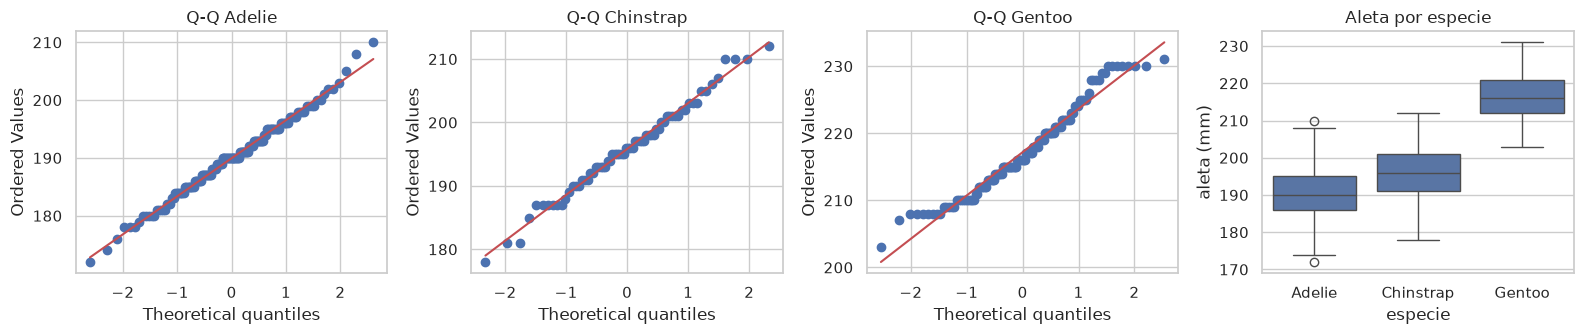

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (especie, grupo) in zip(axes, con_aleta.groupby("species")):
    stats.probplot(grupo["flipper_length_mm"], plot=ax)
    ax.set_title(f"Q-Q {especie}")
sns.boxplot(con_aleta, x="species", y="flipper_length_mm", ax=axes[3])
axes[3].set(xlabel="especie", ylabel="aleta (mm)", title="Aleta por especie")
plt.tight_layout()
plt.show()

**✅ Respuesta sugerida:**

Los puntos siguen la recta en las tres especies, con escalones porque la aleta se mide en milímetros enteros, y las cajas tienen dispersiones parecidas (Levene no rechaza). Con efectos tan grandes (η² ≈ 0.78) y *n* de 68 a 151 por grupo, ninguna desviación menor cambiaría la conclusión.

---
## ✅ Cierre.

**Hoy vimos:**
* La lógica del contraste, qué **no** significa un valor *p*, la potencia y por qué las comparaciones múltiples producen falsos hallazgos.
* Dos grupos: Welch por defecto (Student falla con varianzas y tamaños distintos), Mann-Whitney y permutación.
* Proporciones (*z*) y categóricas (chi cuadrada, revisando las frecuencias esperadas).
* Más de dos grupos: Levene, ANOVA clásico y de Welch, Tukey (por convención, cuando el ANOVA rechaza).
* Tamaño del efecto: d de Cohen, V de Cramér y η²; con *n* enorme, significativo no implica importante.

**Práctica (en Classroom):** completar los tres incisos del ejercicio 1 y aplicar al menos una prueba con su tamaño del efecto a otra comparación de `penguins`, `titanic` o `tips`.

**Siguiente *notebook*:** `23_eda_completo_con_mpg.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>